In [28]:
#importaciones 
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['figure.facecolor'] = 'white'


from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [34]:
sismos = pd.read_csv('sismos_santander_procesado.csv')
df = pd.DataFrame(sismos)


# documentacion de cada variable 

## DICCIONARIO DE VARIABLES - sismos_santander_procesado.csv

### Introduccion: Catalogo de 214.833 sismos registrados en Santander (Colombia) entre 1993 y 2026. Cada fila es un sismo con su ubicacion, magnitud, calidad de la medicion,incertidumbres y una clasificacion de riesgo.

- magnitude        : Magnitud del sismo.
- depth            : Profundidad del sismo, en km.
- latitude         : Latitud del epicentro, en grados.
- longitude        : Longitud del epicentro, en grados.
- rms              : Error promedio de los tiempos de llegada de las ondas (en segundos). Menor es mejor.
- gap              : Mayor hueco angular (0-360 grados) entre las estaciones que lo detectaron. Menor es mejor.
- nst              : Numero de estaciones sismicas que registraron el sismo.
- magnitude_error  : Incertidumbre de la magnitud.
- depth_error      : Incertidumbre de la profundidad (km).
- latitude_error   : Incertidumbre de la latitud (km).
- longitude_error  : Incertidumbre de la longitud (km).
- local_time       : Fecha y hora del sismo.
- nivel_riesgo     : Clasificacion de riesgo del sismo: Bajo, Medio o Alto.


# Exploracion de datos 
------------------------

In [10]:
df.head()

,magnitude,depth,latitude,longitude,rms,gap,nst,magnitude_error,depth_error,latitude_error,longitude_error,local_time,nivel_riesgo
0,1.3,149,6.7948,-73.1283,0.5,190.0,5,0.2,4.0,3.4,3.4,2026-10-09T09:25:19+00:00,Bajo
1,1.4,157,6.7898,-73.1745,0.2,133.0,6,0.1,2.0,1.1,1.1,2026-10-09T08:58:08+00:00,Bajo
2,1.5,159,6.7726,-73.1775,0.4,134.0,7,0.2,3.0,2.0,2.0,2026-10-09T08:53:52+00:00,Bajo
3,1.7,139,6.7733,-73.1369,0.7,139.0,14,0.2,8.0,4.5,7.5,2026-10-09T08:09:07+00:00,Bajo
4,2.3,142,6.7617,-73.1444,0.9,65.0,36,0.2,5.0,2.9,3.4,2026-10-09T07:36:31+00:00,Bajo


In [11]:
#ultimos del df
df.tail()

,magnitude,depth,latitude,longitude,rms,gap,nst,magnitude_error,depth_error,latitude_error,longitude_error,local_time,nivel_riesgo
214828,3.1,152,6.790,-73.077,0.3,299.0,5,NaN,8.0,0.1,0.1,1993-06-01T11:07:52+00:00,Bajo
214829,4.4,150,6.754,-73.058,0.5,308.0,9,NaN,8.0,0.1,0.1,1993-06-01T10:31:24+00:00,Medio
214830,2.9,150,6.894,-73.171,0.3,308.0,4,NaN,8.0,0.1,0.1,1993-06-01T05:34:45+00:00,Bajo
214831,2.9,152,6.839,-73.105,0.5,321.0,4,NaN,11.0,0.1,0.1,1993-06-01T05:13:18+00:00,Bajo
214832,2.6,144,6.793,-73.151,0.3,314.0,4,NaN,7.0,0.1,0.1,1993-06-01T01:53:08+00:00,Bajo


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 214833 entries, 0 to 214832
Data columns (total 13 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   magnitude        214833 non-null  float64
 1   depth            214833 non-null  int64  
 2   latitude         214833 non-null  float64
 3   longitude        214833 non-null  float64
 4   rms              214833 non-null  float64
 5   gap              214824 non-null  float64
 6   nst              214833 non-null  int64  
 7   magnitude_error  105629 non-null  float64
 8   depth_error      214563 non-null  float64
 9   latitude_error   214822 non-null  float64
 10  longitude_error  214822 non-null  float64
 11  local_time       214833 non-null  str    
 12  nivel_riesgo     214833 non-null  str    
dtypes: float64(9), int64(2), str(2)
memory usage: 27.3 MB


In [35]:
# n_filas    → número de filas del DataFrame
n_filas = df.shape[0]

# n_columnas → número de columnas del DataFrame
n_columnas = df.shape[1]

# precio_max → precio por m² más alto de la tabla
precio_max = df['depth'].max()

# precio_min → precio por m² más bajo de la tabla
precio_min = df['depth'].min()

# ────────────────────────────────────────────────────────────────────────────
print(f'Filas: {n_filas} | Columnas: {n_columnas}')
print(f'Profundidad maxima del sismo, en km.: {precio_max} ')
print(f'Profundidad minima del sismo, en km.: {precio_min} ')

Filas: 214833 | Columnas: 13
Profundidad maxima del sismo, en km.: 436 
Profundidad minima del sismo, en km.: -5 


# Correlaciones 
-------

Correlación de cada variable con depth:
  longitude      : +0.676
  latitude       : +0.253
  magnitude      : +0.247
  gap            : +0.196
  longitude_error: -0.005
  latitude_error : -0.014
  rms            : -0.019
  nst            : -0.040
  depth_error    : -0.051
  magnitude_error: -0.078

→ Mejor predictor: 'longitude'


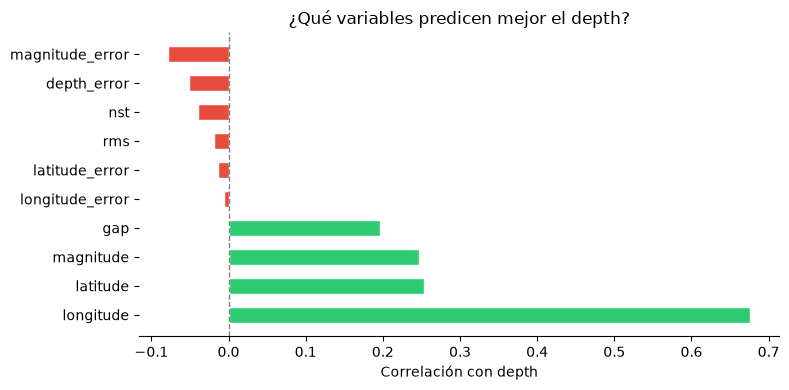

In [36]:
import seaborn as sns

# Calcular correlaciones con la magnitud

# Seleccionar únicamente las columnas numéricas
df_numerico = df.select_dtypes(include="number")

correlaciones = df_numerico.corr()['depth'].drop('depth')
correlaciones_ordenadas = correlaciones.sort_values(ascending=False)
mejor_predictor = correlaciones_ordenadas.abs().idxmax()

print('Correlación de cada variable con depth:')
for col, val in correlaciones_ordenadas.items():
    print(f'  {col:15s}: {val:+.3f}')
print(f"\n→ Mejor predictor: '{mejor_predictor}'")

# Gráfico: barras horizontales coloreadas por signo
colores = ['#2ECC71' if v > 0 else '#E74C3C' for v in correlaciones_ordenadas.values]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(correlaciones_ordenadas.index, correlaciones_ordenadas.values,
        color=colores, edgecolor='white', height=0.55)
ax.axvline(0, color='gray', linewidth=1, linestyle='--')
ax.set_xlabel('Correlación con depth')
ax.set_title('¿Qué variables predicen mejor el depth?')
sns.despine(left=True)
plt.tight_layout()
plt.show()

In [37]:
features = [
    'magnitude', 'depth', 'latitude', 'longitude', 
    'rms', 'gap', 'nst', 'magnitude_error', 
    'depth_error', 'latitude_error', 'longitude_error'
]
X = df[features].fillna(0) # Rellenar nulos residuales de errores técnicos
y = df['nivel_riesgo']
# 5. Dividir los datos en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)



In [38]:
# 6. Entrenar un modelo supervisado (Random Forest Classifier)
print("Entrenando el modelo...")
modelo = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10)
modelo.fit(X_train, y_train)



Entrenando el modelo...


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap

In [39]:
# 7. Evaluar el modelo con el conjunto de prueba
y_pred = modelo.predict(X_test)

print(f"\nExactitud (Accuracy): {accuracy_score(y_test, y_pred):.4f}")
print("\nMatriz de Confusión:")
print(confusion_matrix(y_test, y_pred))
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred))


Exactitud (Accuracy): 0.9998

Matriz de Confusión:
[[  382     0     9]
 [    0 35257     0]
 [    0     0  7319]]

Reporte de Clasificación:
              precision    recall  f1-score   support

        Alto       1.00      0.98      0.99       391
        Bajo       1.00      1.00      1.00     35257
       Medio       1.00      1.00      1.00      7319

    accuracy                           1.00     42967
   macro avg       1.00      0.99      1.00     42967
weighted avg       1.00      1.00      1.00     42967

